# 04 · XAI y evaluación cross-domain
**Responsable: Felipe Aguilar.** Se recalculan resultados reales de los CSV entregados; no se entrena ni se ajustan umbrales sobre test.

Este notebook se puede ejecutar sin fotos para consolidar las predicciones. Grad-CAM, Guatemala y nuevas latencias requieren imágenes y checkpoints: su ausencia se registra como pendiente, nunca como un resultado. Consulte `docs/XAI_EVALUACION.md` para ejecutar esas etapas y defender los hallazgos.

**EfficientNet-B0:** ya fue entrenada con RDD2022 local verificado; sus resultados completos están bajo `reports/experiments/efficientnet/` y entran en esta consolidación. El protocolo, los 36 Grad-CAM reales y los benchmarks CPU/MPS se documentan en `docs/EFFICIENTNET.md`. El VAE se conserva como resultado negativo.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (ROOT / 'src/evaluation/cross_domain.py').is_file(), 'Abra el notebook desde el repositorio'
sys.path.insert(0, str(ROOT))
from src.evaluation.cross_domain import run
OUT = ROOT / 'reports/xai_evaluation'
metrics, status = run(output=OUT)


             experiment_id            split    n  precision   recall       f1   pr_auc  flagged_rate
         exp1_scratch_fp32          test_id 4174   0.421462 0.539841 0.473362 0.487396      0.154049
         exp1_scratch_fp32         test_ood 8161   0.029945 0.148438 0.049836 0.030351      0.155496
         exp1_scratch_fp32 test_perspective 2401   0.033301 0.531250 0.062673 0.026546      0.425239
         exp1_scratch_fp32              val 4173   0.441315 0.559524 0.493438 0.513670      0.153127
      exp2_pretrained_fp32          test_id 4174   0.630189 0.665339 0.647287 0.707188      0.126977
      exp2_pretrained_fp32         test_ood 8161   0.100000 0.015625 0.027027 0.054203      0.004901
      exp2_pretrained_fp32 test_perspective 2401   0.117647 0.593750 0.196382 0.271242      0.134527
      exp2_pretrained_fp32              val 4173   0.684411 0.714286 0.699029 0.762837      0.126048
         exp3_augment_fp32          test_id 4174   0.611511 0.677291 0.642722 0.733475     

## Protocolo y lectura de las métricas
Se verifica `dataset_v1`, sus hashes, cobertura completa y etiquetas. Umbral fijo elegido por F1 en `val`; selección de clasificadores ResNet/EfficientNet por AP de `val`. `test_ood` es Noruega, `test_perspective` es China_Drone; ninguno representa Guatemala.

AP (`pr_auc`) es average precision de sklearn, no área trapezoidal. Contrastar con prevalencia. Recall alto con casi todas las imágenes positivas puede ser degenerado. ΔF1 = F1 interno − F1 externo: positivo significa caída, en unidades absolutas. Cambios de prevalencia afectan F1 y precisión; la caída sola no demuestra su causa visual.

,experiment_id,split,n,prevalence,precision,recall,f1,pr_auc,fpr,flagged_rate
0,exp1_scratch_fp32,test_id,4174,0.1203,0.4215,0.5398,0.4734,0.4874,0.1013,0.1540
1,exp1_scratch_fp32,test_ood,8161,0.0314,0.0299,0.1484,0.0498,0.0304,0.1557,0.1555
2,exp1_scratch_fp32,test_perspective,2401,0.0267,0.0333,0.5312,0.0627,0.0265,0.4223,0.4252
3,exp1_scratch_fp32,val,4173,0.1208,0.4413,0.5595,0.4934,0.5137,0.0973,0.1531
4,exp2_pretrained_fp32,test_id,4174,0.1203,0.6302,0.6653,0.6473,0.7072,0.0534,0.1270
5,exp2_pretrained_fp32,test_ood,8161,0.0314,0.1000,0.0156,0.0270,0.0542,0.0046,0.0049
6,exp2_pretrained_fp32,test_perspective,2401,0.0267,0.1176,0.5938,0.1964,0.2712,0.1220,0.1345
7,exp2_pretrained_fp32,val,4173,0.1208,0.6844,0.7143,0.6990,0.7628,0.0452,0.1260
8,exp3_augment_fp32,test_id,4174,0.1203,0.6115,0.6773,0.6427,0.7335,0.0588,0.1332
9,exp3_augment_fp32,test_ood,8161,0.0314,0.0893,0.0391,0.0543,0.0542,0.0129,0.0137


,family,experiment_id,domain,f1_id,f1_external,delta_f1,recall_id,recall_external,delta_recall,prevalence_id,prevalence_external
0,efficientnet,efficientnet_b0_pretrained,test_ood,0.6444,0.0744,0.5700,0.6733,0.0586,0.6147,0.1203,0.0314
1,efficientnet,efficientnet_b0_pretrained,test_perspective,0.6444,0.2405,0.4039,0.6733,0.5938,0.0796,0.1203,0.0267
2,resnet,exp1_scratch_fp32,test_ood,0.4734,0.0498,0.4235,0.5398,0.1484,0.3914,0.1203,0.0314
3,resnet,exp1_scratch_fp32,test_perspective,0.4734,0.0627,0.4107,0.5398,0.5312,0.0086,0.1203,0.0267
4,resnet,exp2_pretrained_fp32,test_ood,0.6473,0.0270,0.6203,0.6653,0.0156,0.6497,0.1203,0.0314
5,resnet,exp2_pretrained_fp32,test_perspective,0.6473,0.1964,0.4509,0.6653,0.5938,0.0716,0.1203,0.0267
6,resnet,exp3_augment_fp32,test_ood,0.6427,0.0543,0.5884,0.6773,0.0391,0.6382,0.1203,0.0314
7,resnet,exp3_augment_fp32,test_perspective,0.6427,0.2818,0.3609,0.6773,0.6406,0.0367,0.1203,0.0267
8,resnet,exp4_auxiliary_fp32,test_ood,0.6504,0.0217,0.6287,0.6633,0.0117,0.6516,0.1203,0.0314
9,resnet,exp4_auxiliary_fp32,test_perspective,0.6504,0.2458,0.4046,0.6633,0.4531,0.2102,0.1203,0.0267


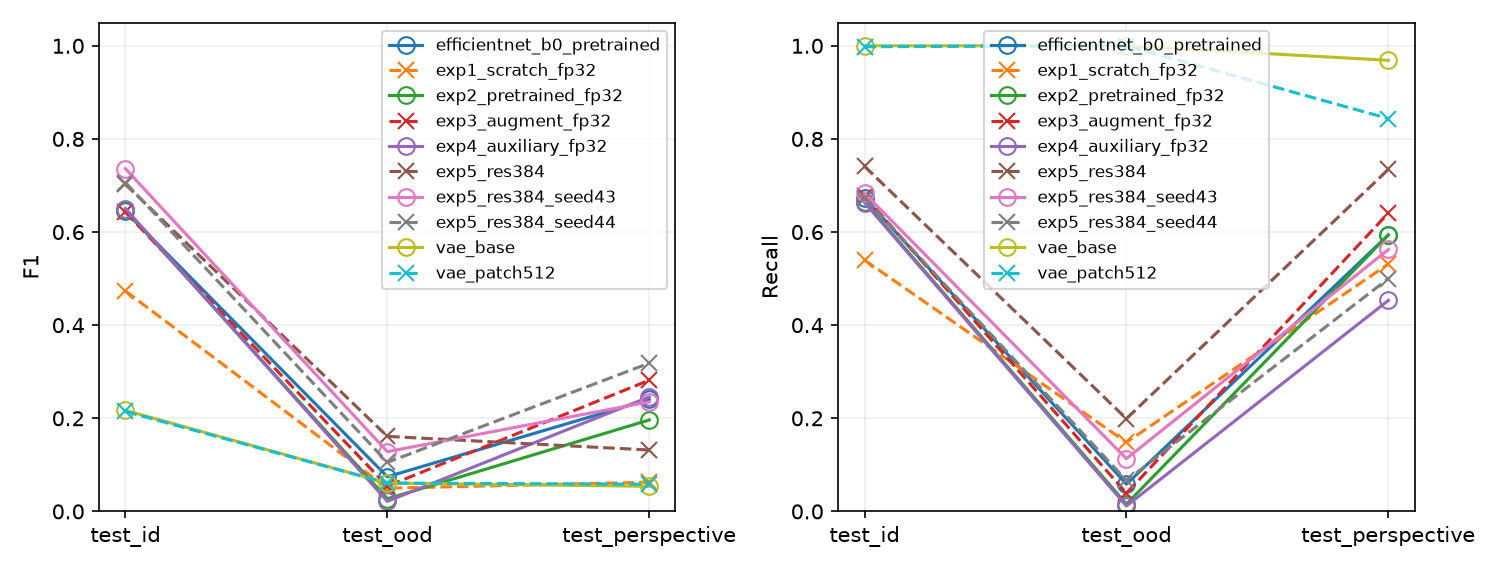

In [2]:
display(metrics[['experiment_id', 'split', 'n', 'prevalence', 'precision', 'recall', 'f1', 'pr_auc', 'fpr', 'flagged_rate']].round(4))
display(pd.read_csv(OUT / 'domain_shift.csv').round(4))
display(Image(filename=str(OUT / 'comparison.png')))


### exp1_scratch_fp32

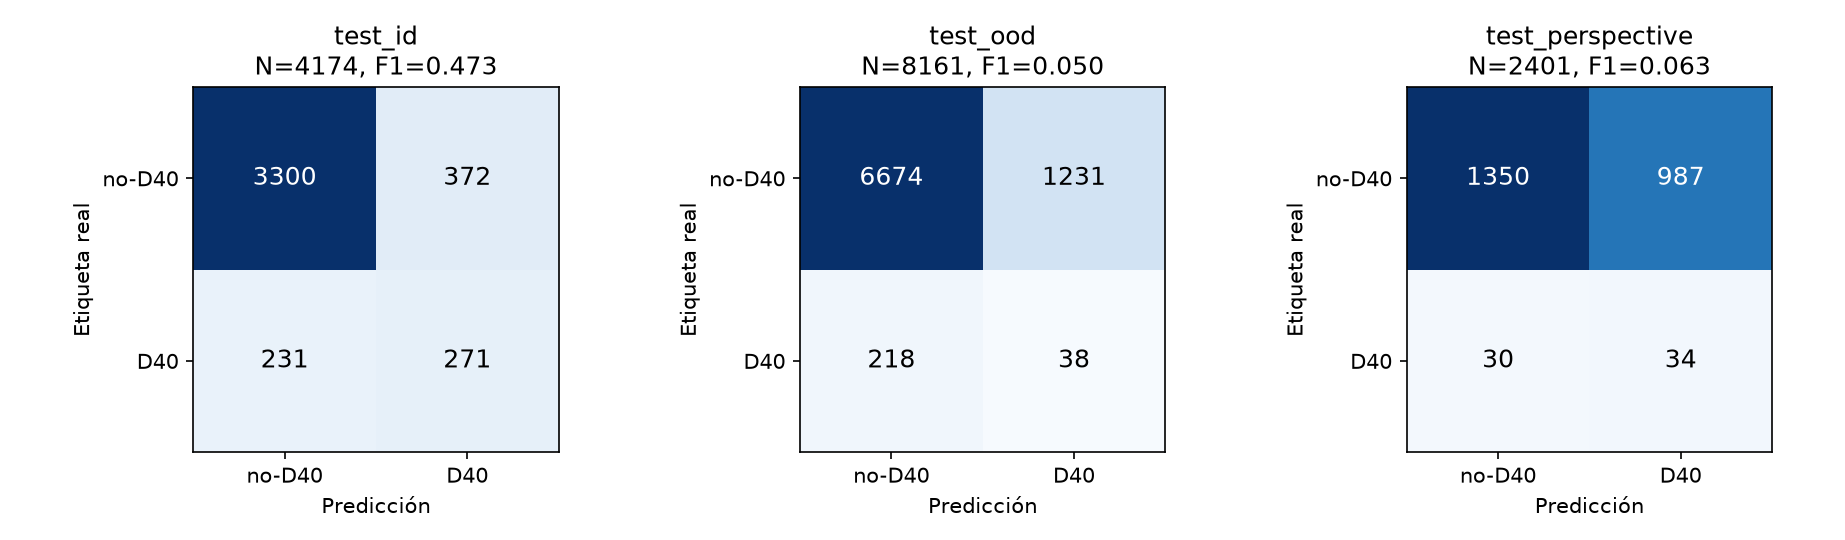

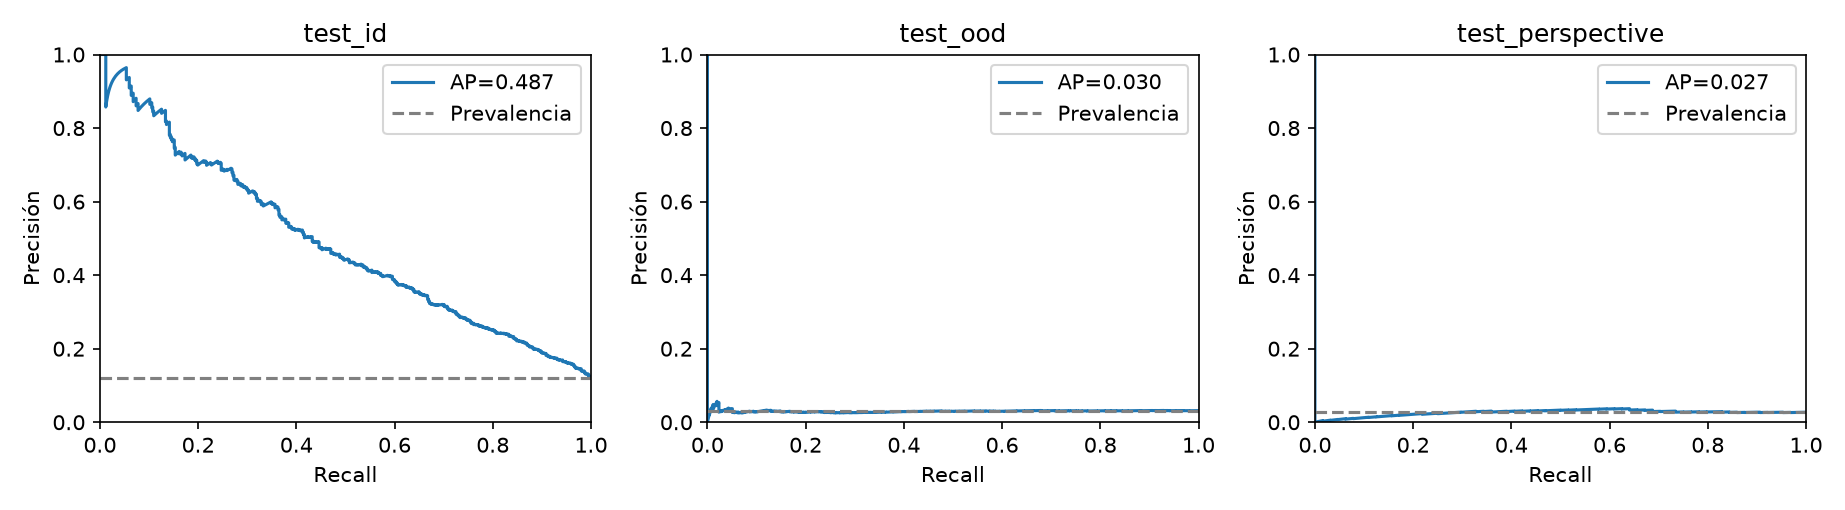

### exp2_pretrained_fp32

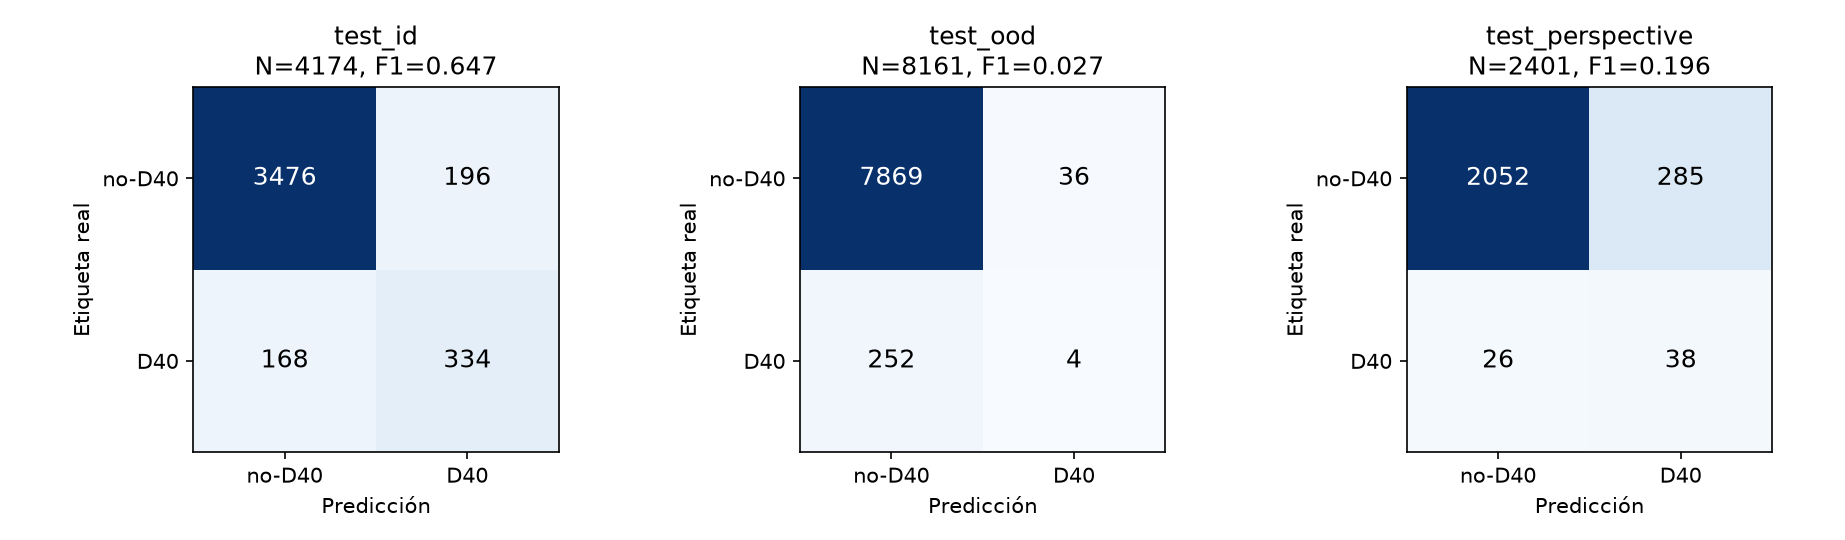

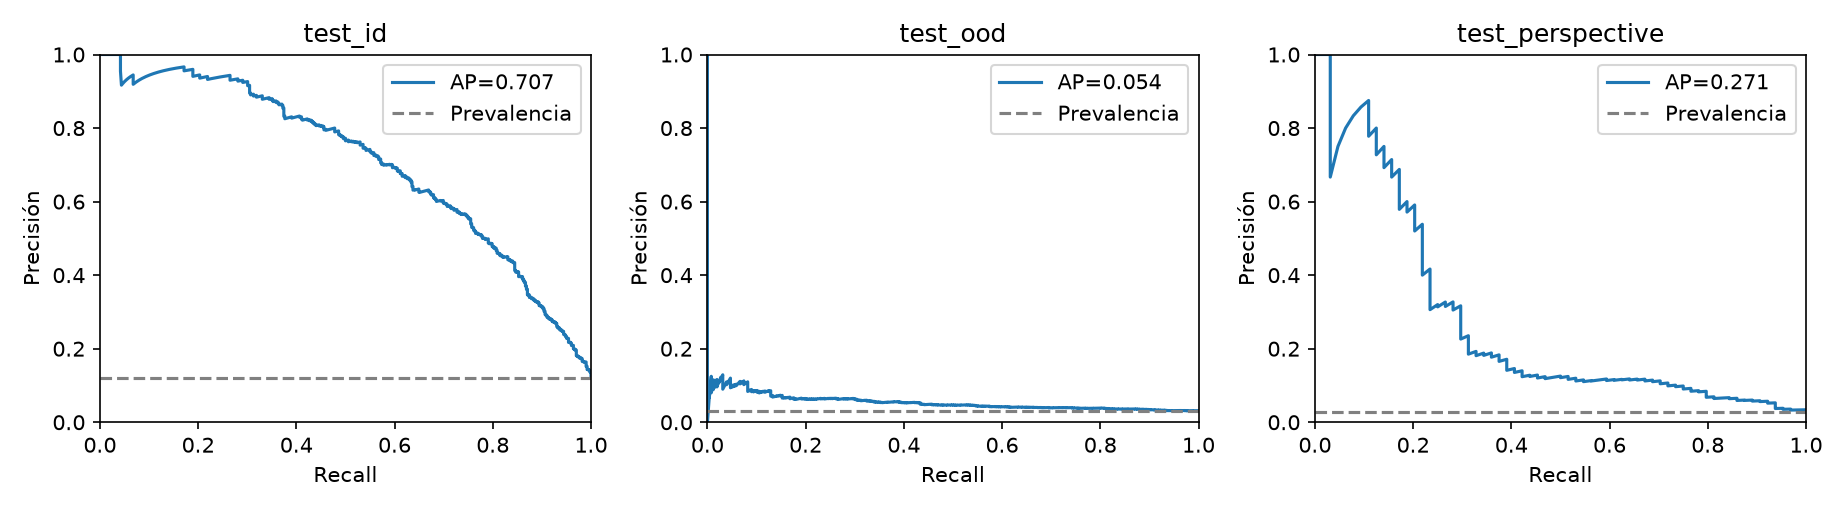

### exp3_augment_fp32

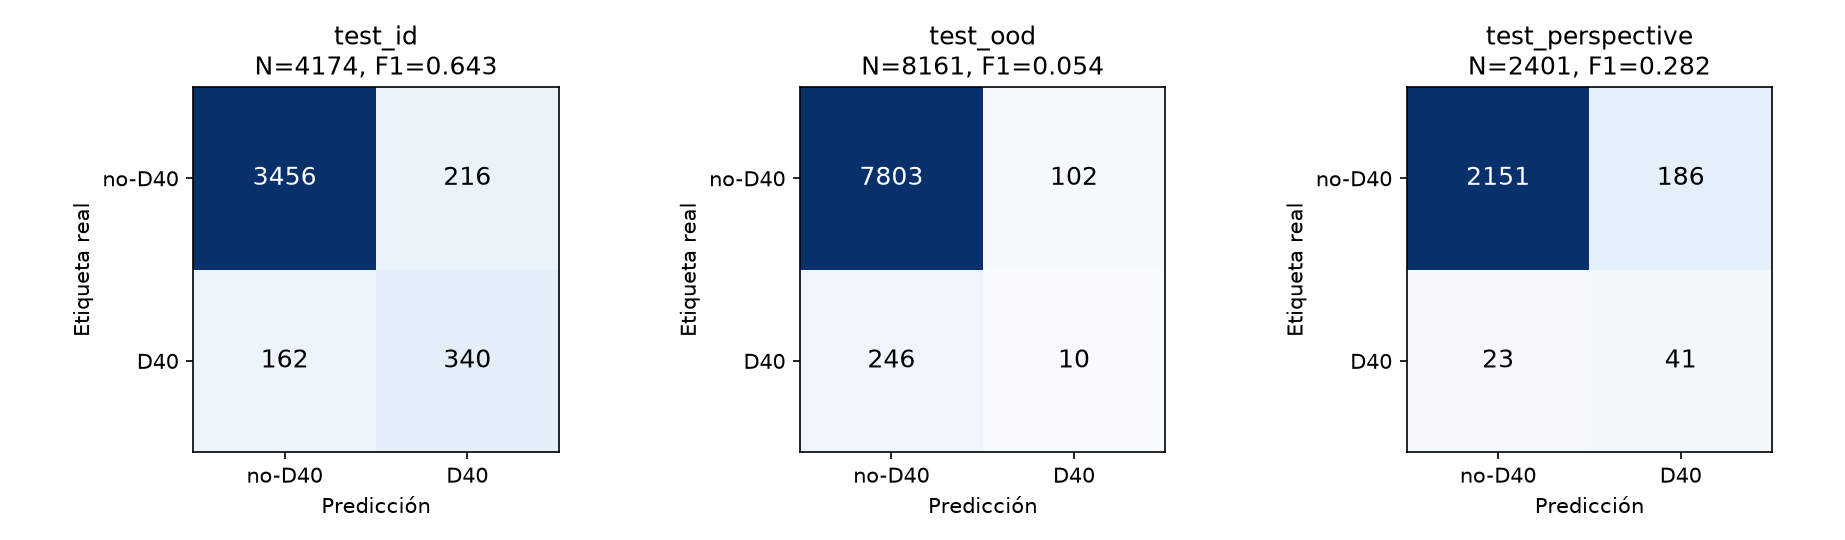

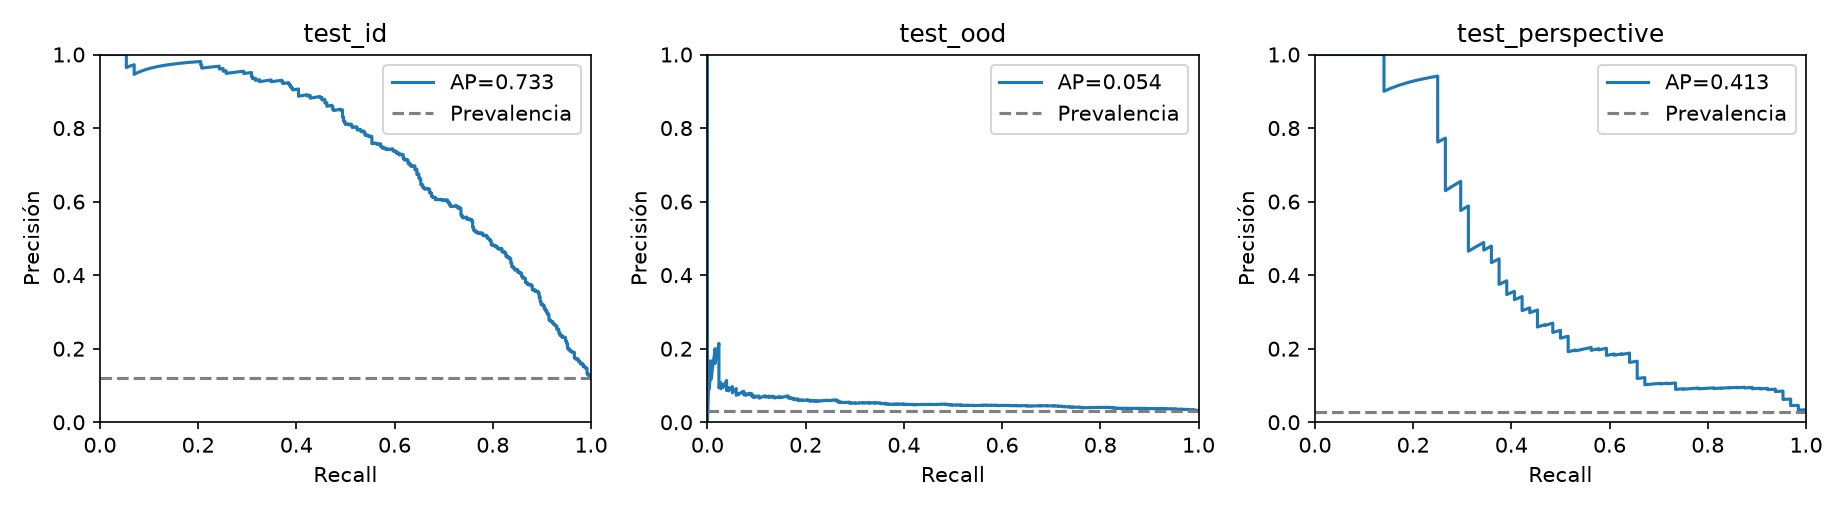

### exp4_auxiliary_fp32

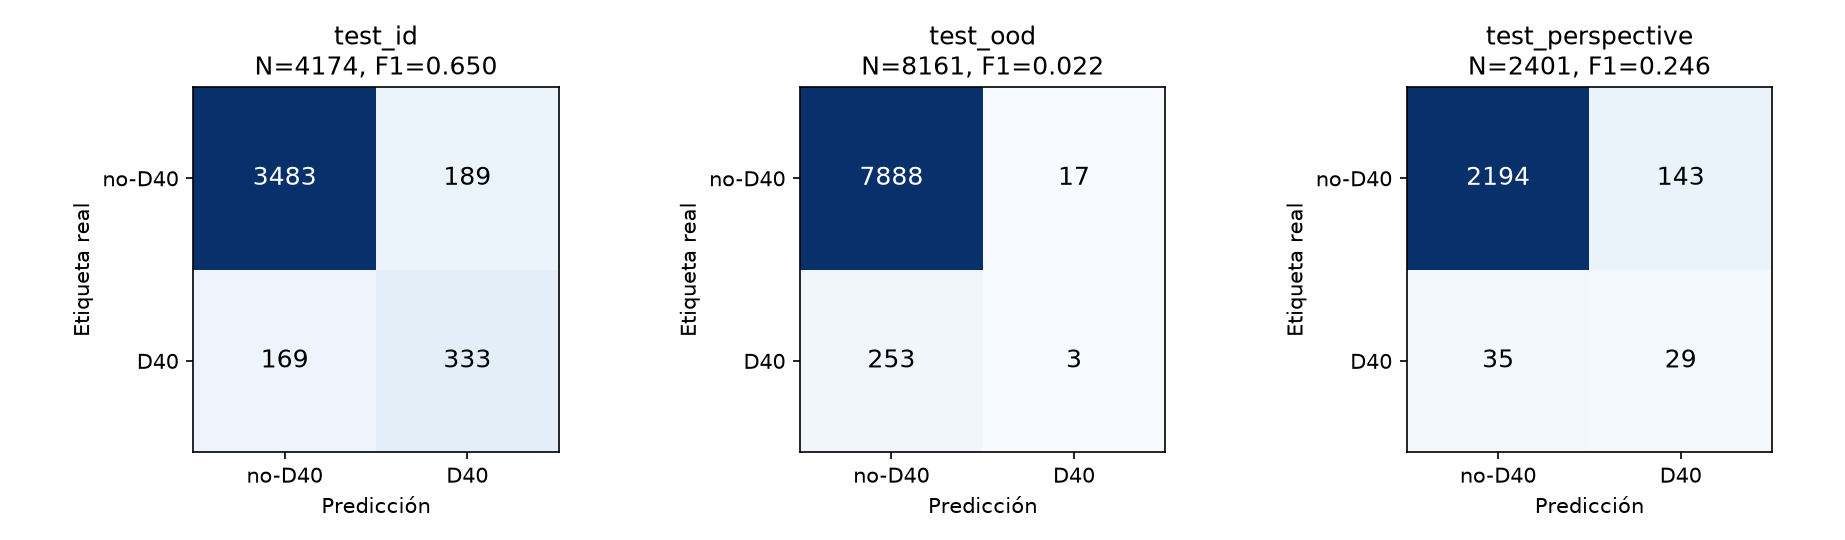

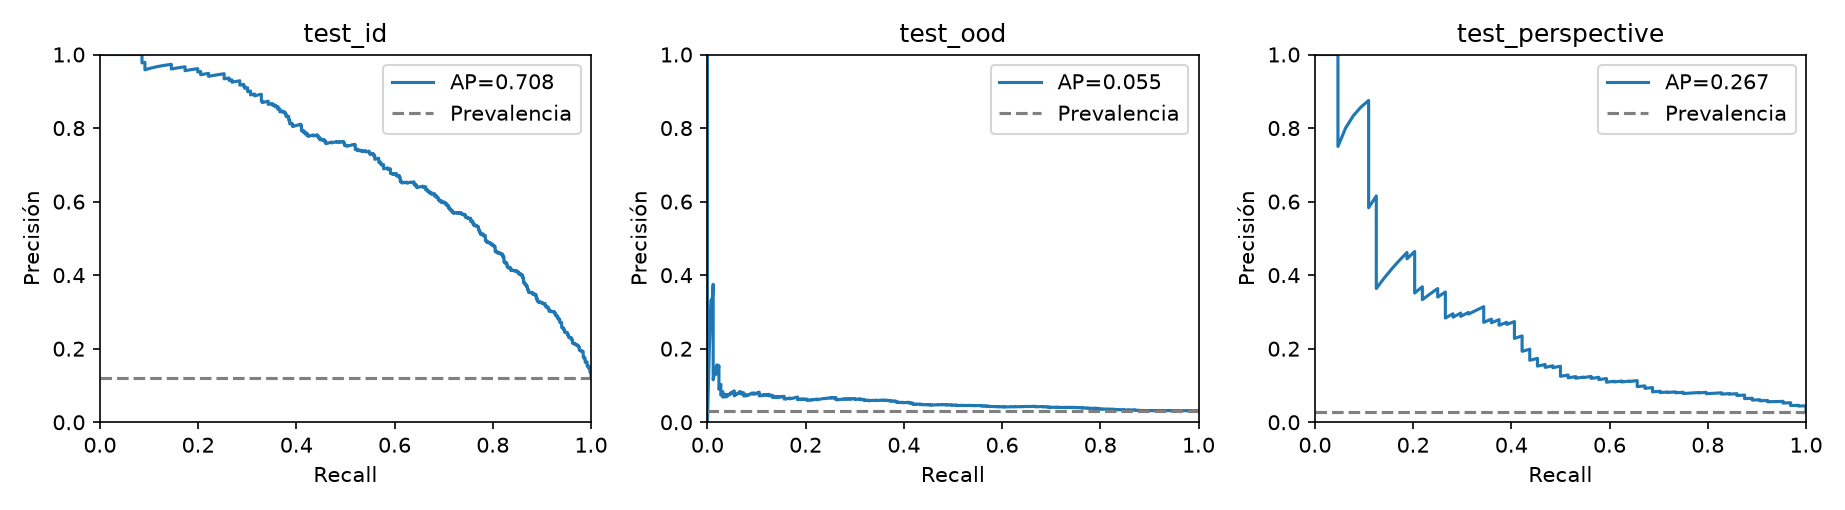

### exp5_res384

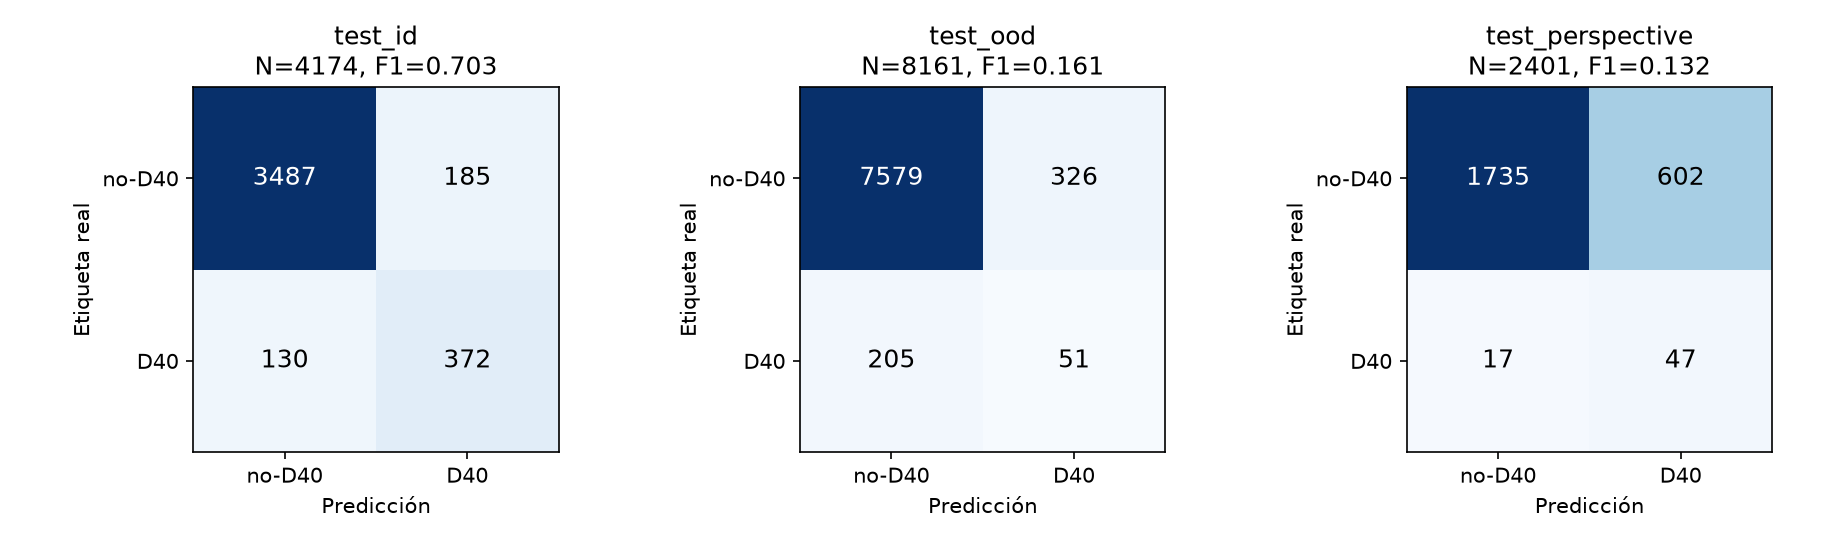

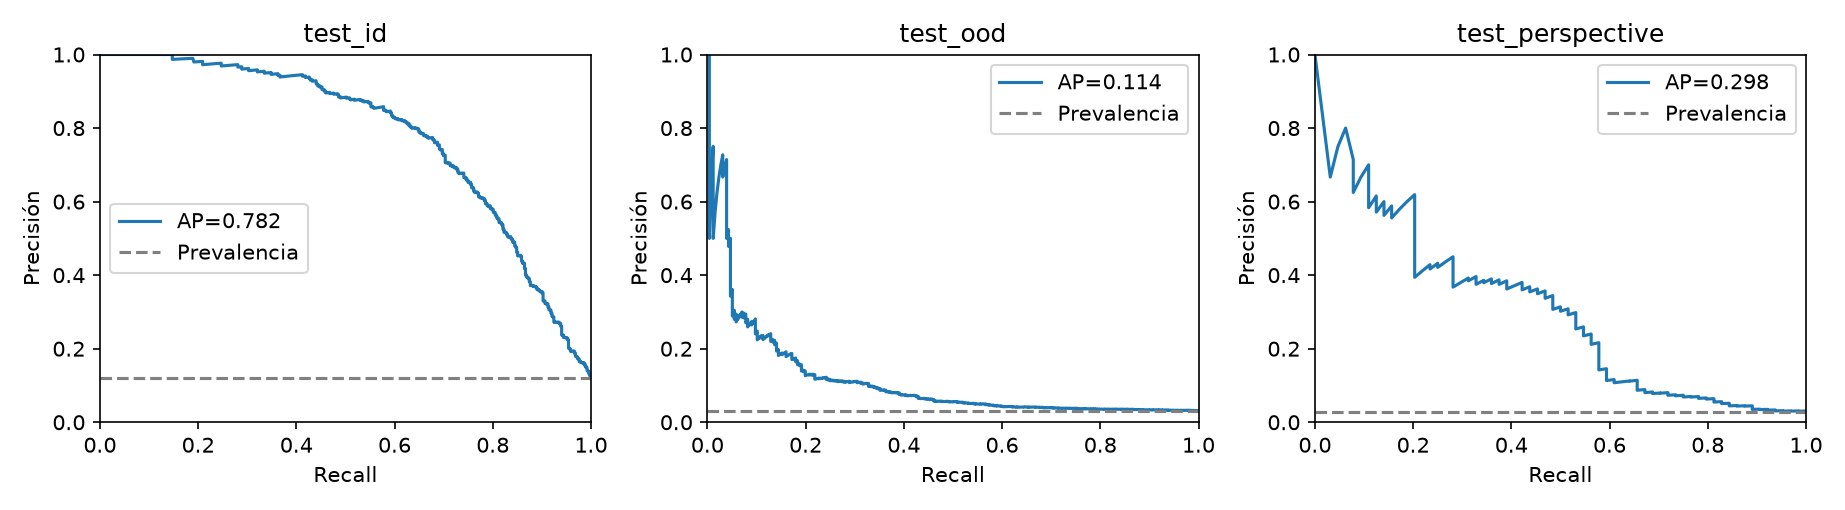

### exp5_res384_seed43

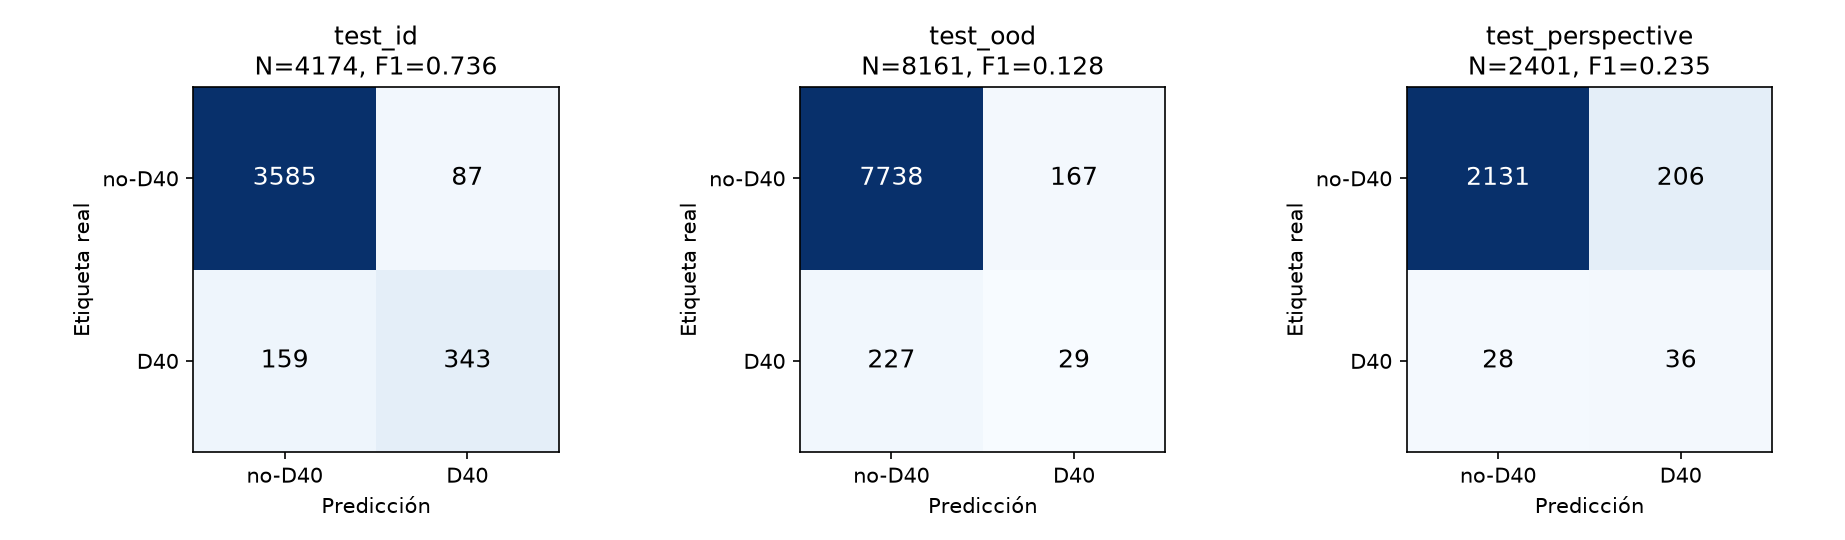

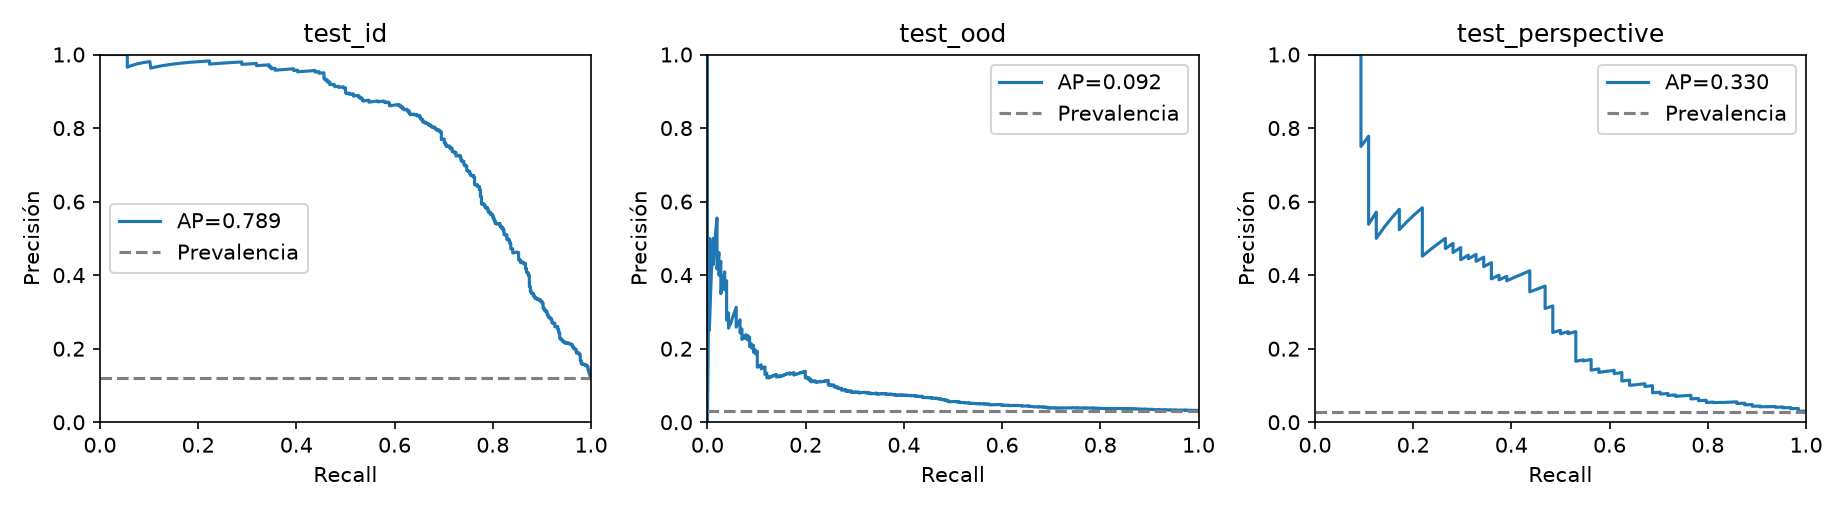

### exp5_res384_seed44

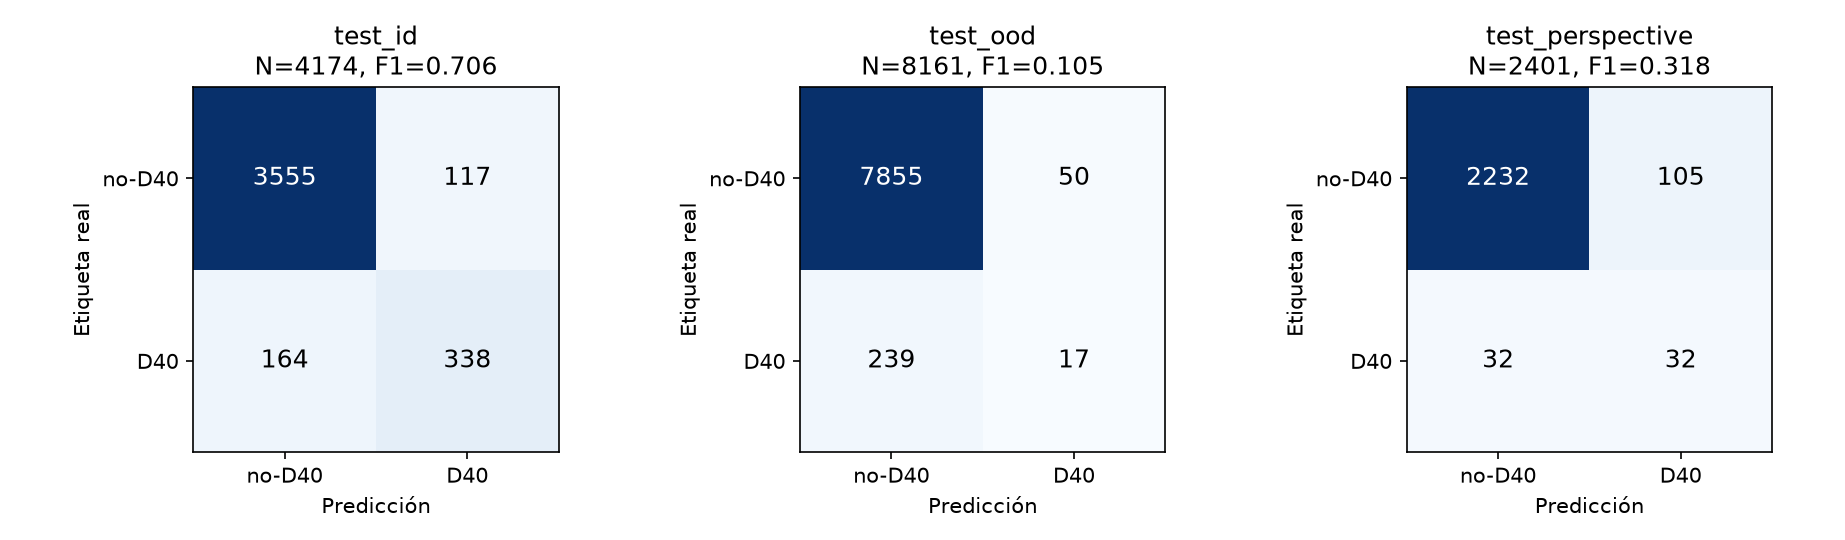

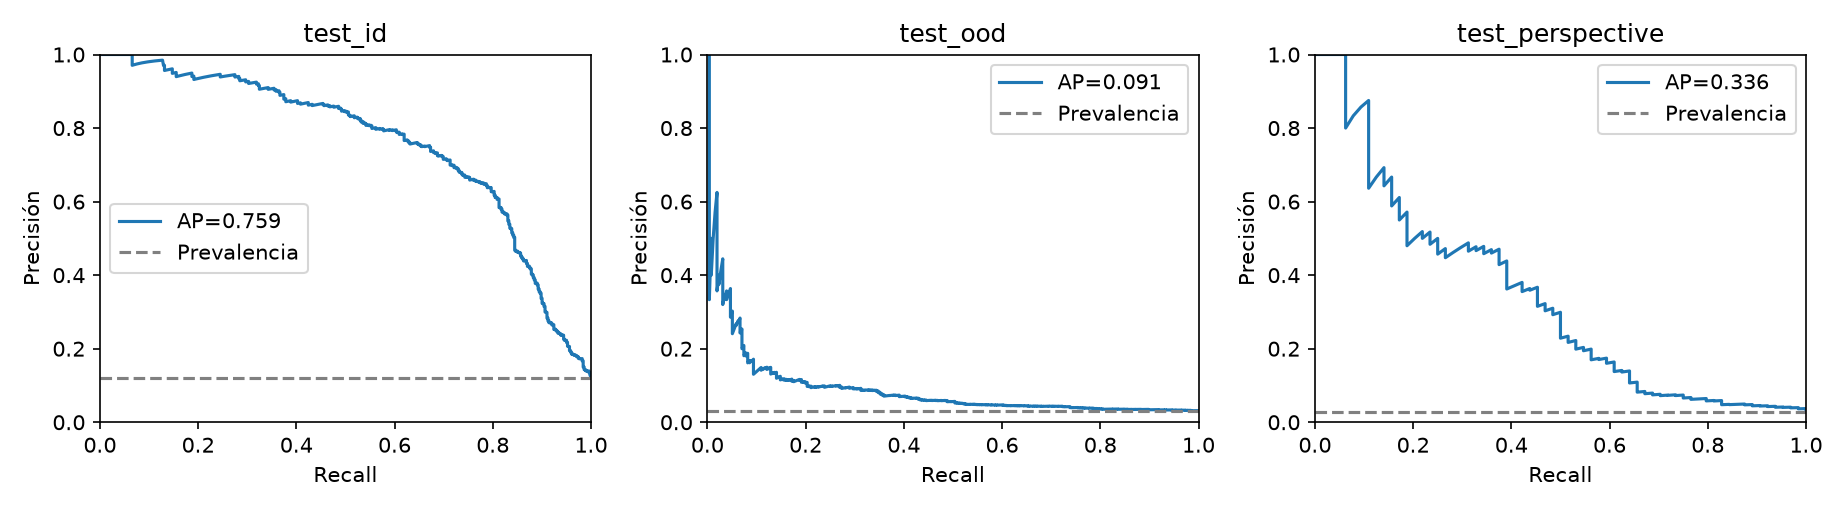

### efficientnet_b0_pretrained

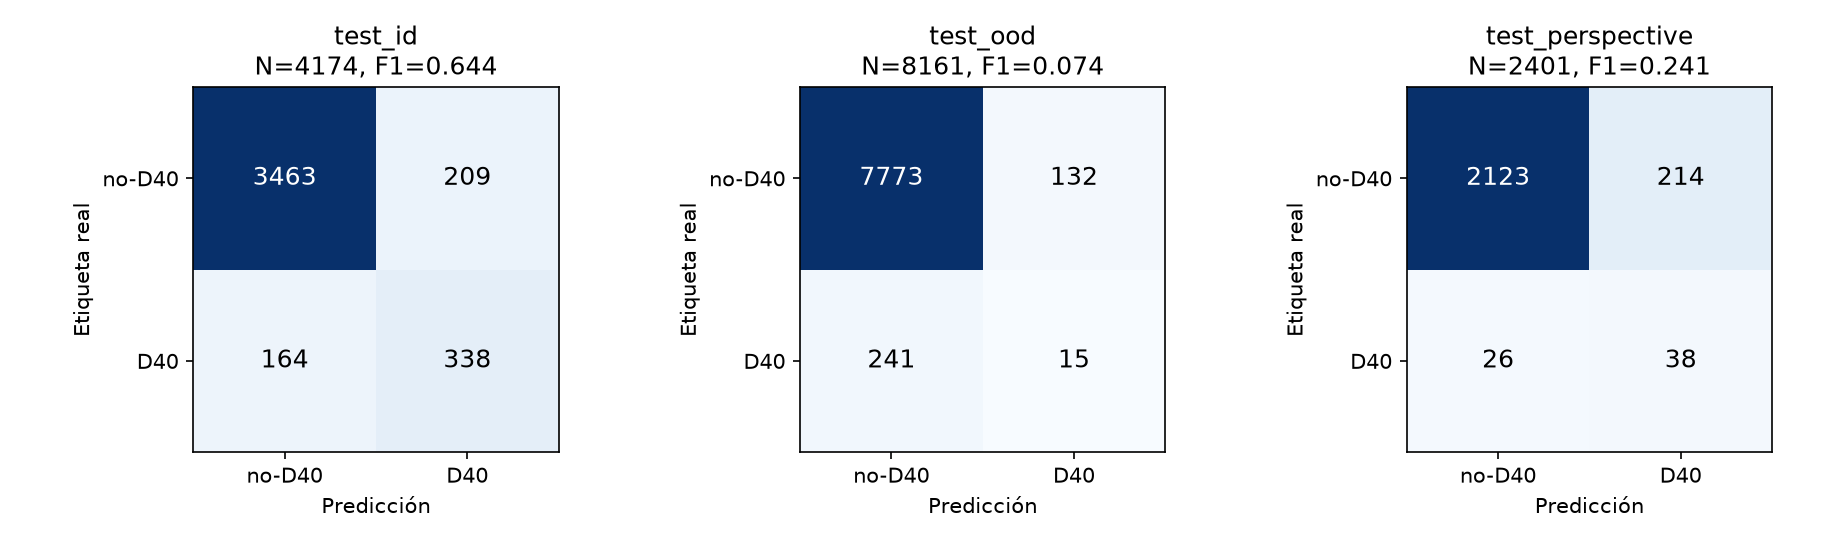

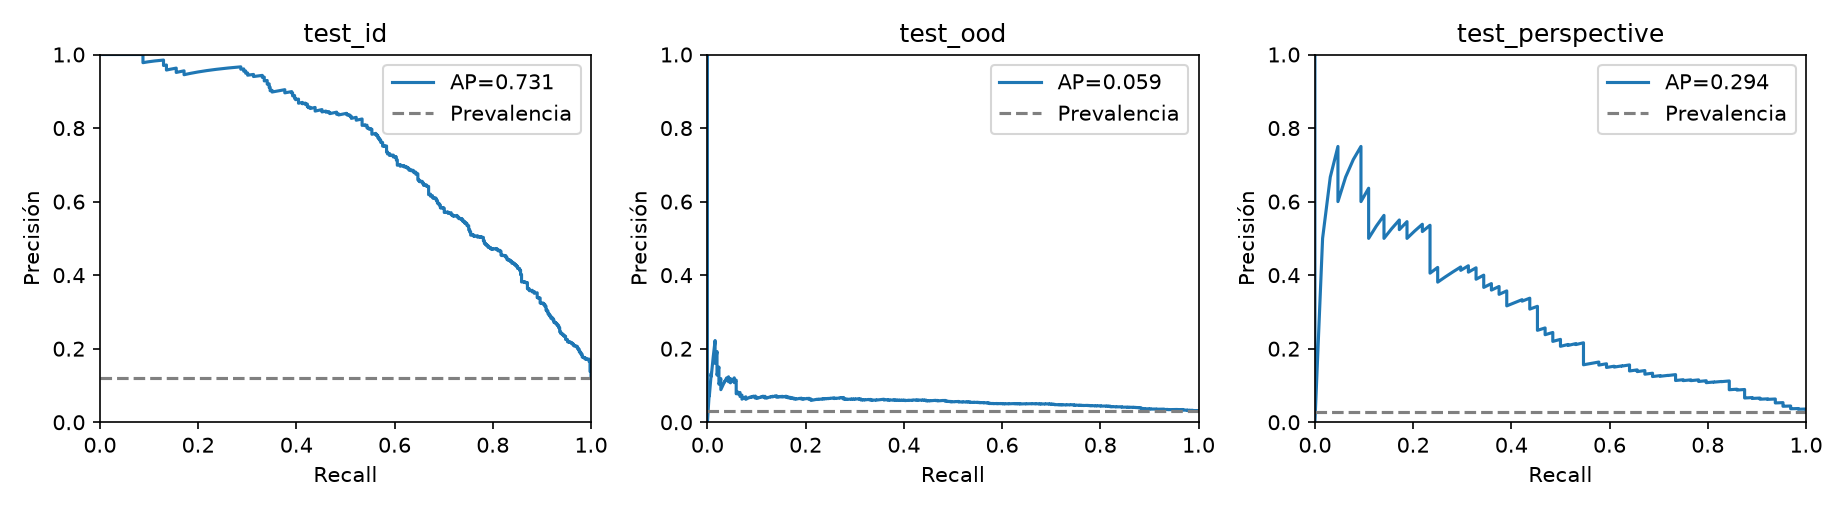

### vae_base

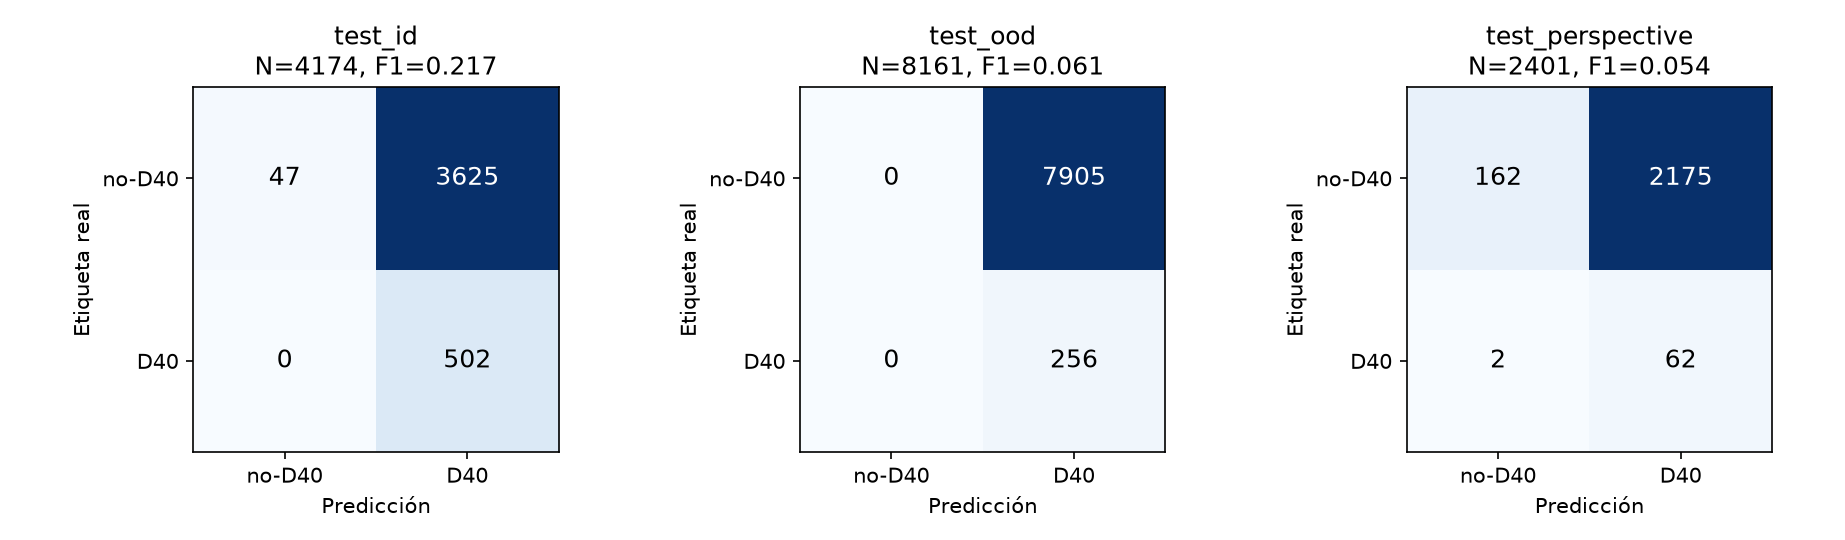

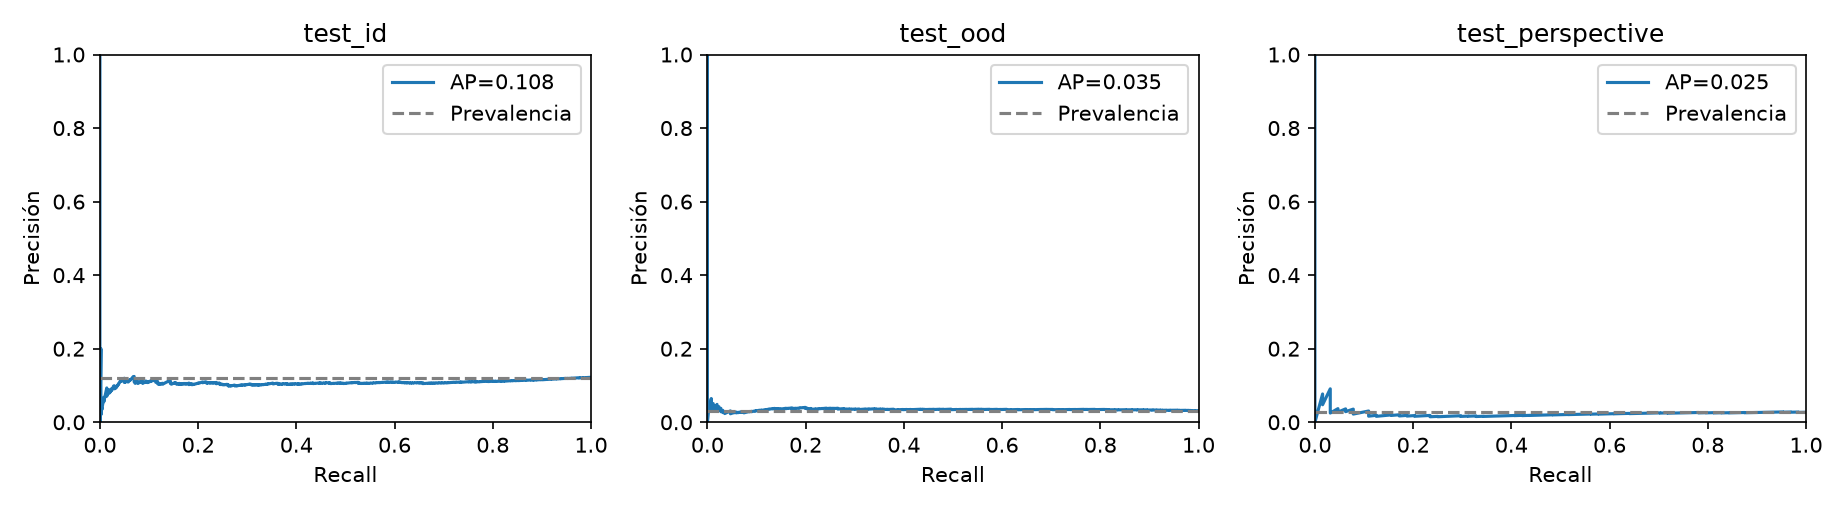

### vae_patch512

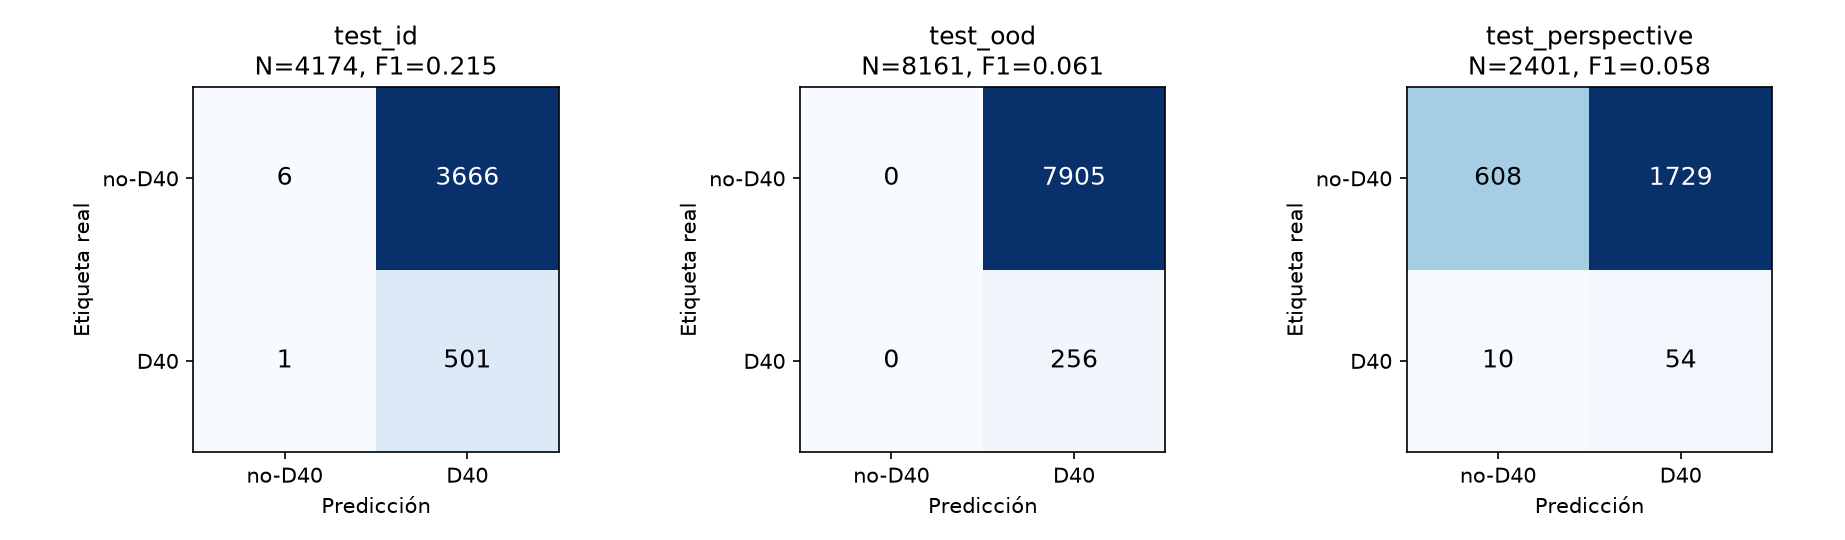

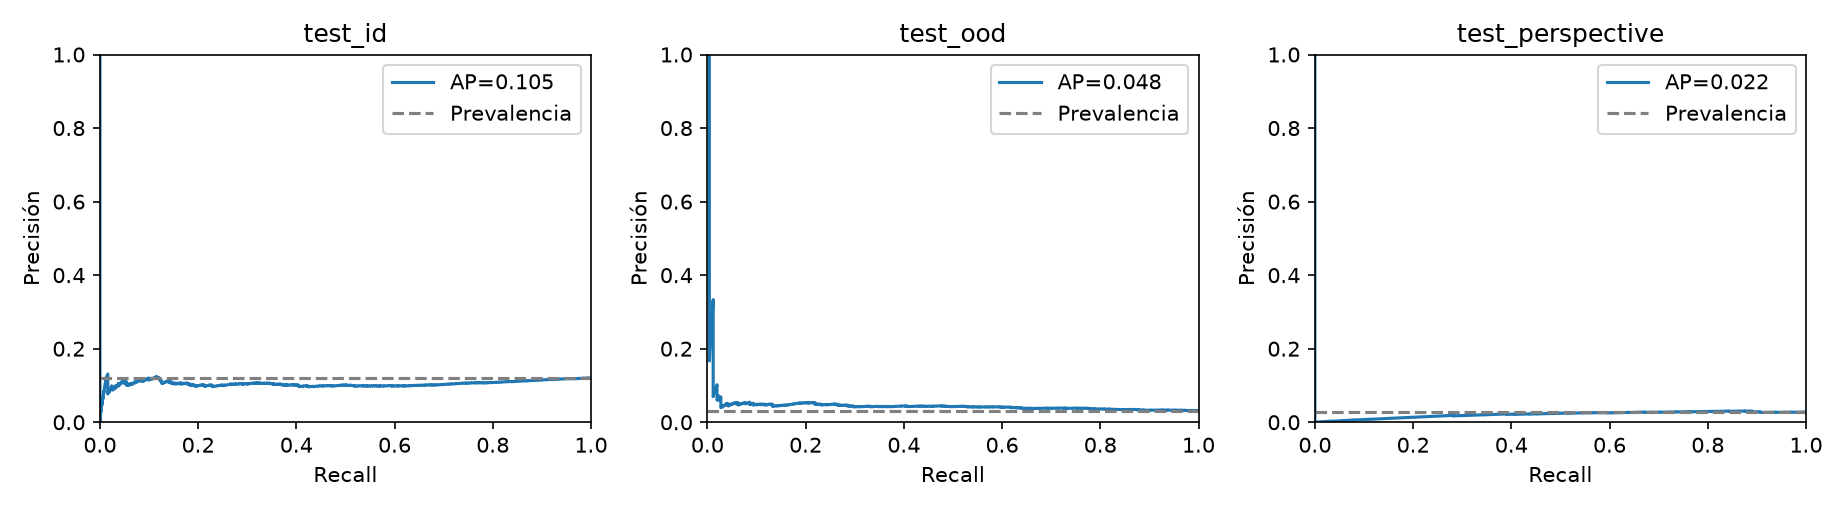

In [3]:
for experiment in metrics.experiment_id.unique():
    display(Markdown(f'### {experiment}'))
    display(Image(filename=str(OUT / experiment / 'confusion.png')))
    display(Image(filename=str(OUT / experiment / 'precision_recall.png')))


## Errores, selección de casos y auditoría
Los ejemplos son una muestra uniforme reproducible (semilla 42) de hasta tres TP/TN/FP/FN por dominio. Si un grupo está vacío se informa: no se cambia el umbral para fabricar ejemplos. `error_groups.json` desglosa otros daños y países; las clases de daño pueden solaparse. La explicación visual de sombras, textura o fondo requiere abrir la foto y el mapa, no inferirla de un CSV.

`archive_discrepancies.csv` conserva diferencias entre los números archivados y los recalculados. En `vae_base/val` hay un caso en el límite numérico del umbral: el CSV leído en float64 da 502 TP/2 FN frente a 503 TP/1 FN archivados. Se preservan scores y umbral, sin corregir a mano. Los tres tests de ambos VAE reproducen las matrices archivadas.

In [4]:
display(pd.read_csv(OUT / 'case_coverage.csv'))
display(pd.read_csv(OUT / 'cases.csv')[['experiment_id', 'sample_id', 'split', 'outcome', 'y_score', 'threshold']])
display(pd.read_csv(OUT / 'archive_discrepancies.csv'))
display(pd.read_csv(OUT / 'latency_reported.csv'))
print(json.dumps(status, indent=2, ensure_ascii=False))


,experiment_id,split,outcome,available
0,exp1_scratch_fp32,test_id,TP,271
1,exp1_scratch_fp32,test_id,TN,3300
2,exp1_scratch_fp32,test_id,FP,372
3,exp1_scratch_fp32,test_id,FN,231
4,exp1_scratch_fp32,test_ood,TP,38
...,...,...,...,...
155,vae_patch512,test_perspective,FN,10
156,vae_patch512,val,TP,504
157,vae_patch512,val,TN,4
158,vae_patch512,val,FP,3665


,experiment_id,sample_id,split,outcome,y_score,threshold
0,exp1_scratch_fp32,United_States__United_States_001439,test_id,FN,0.007981,0.428709
1,exp1_scratch_fp32,India__India_005886,test_id,FN,0.000716,0.428709
2,exp1_scratch_fp32,Czech__Czech_002577,test_id,FN,0.003248,0.428709
3,exp1_scratch_fp32,Japan__Japan_010128,test_id,FP,0.974490,0.428709
4,exp1_scratch_fp32,India__India_000145,test_id,FP,0.607679,0.428709
...,...,...,...,...,...,...
337,vae_patch512,China_Drone__China_Drone_000042,test_perspective,TN,0.002684,0.003435
338,vae_patch512,China_Drone__China_Drone_000778,test_perspective,TN,0.001539,0.003435
339,vae_patch512,China_Drone__China_Drone_000955,test_perspective,TP,0.003756,0.003435
340,vae_patch512,China_Drone__China_Drone_002145,test_perspective,TP,0.005355,0.003435


,experiment_id,split,metric,archived,recomputed
0,vae_base,val,tp,503.000000,502.000000
1,vae_base,val,fn,1.000000,2.000000
2,vae_base,val,f1,0.217373,0.216987
3,vae_base,val,precision,0.121969,0.121756
4,vae_base,val,recall,0.998016,0.996032


,experiment_id,device,reported_median_ms,image_size,scope,comparability
0,exp1_scratch_fp32,cpu,63.428250,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
1,exp1_scratch_fp32,cuda,4.915400,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
2,exp2_pretrained_fp32,cpu,32.042700,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
3,exp2_pretrained_fp32,cuda,5.999500,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
4,exp3_augment_fp32,cpu,29.755850,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
5,exp3_augment_fp32,cuda,5.632500,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
6,exp4_auxiliary_fp32,cpu,29.725900,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
7,exp4_auxiliary_fp32,cuda,5.616350,224,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
8,exp5_res384,cpu,70.343000,384,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...
9,exp5_res384,cuda,6.262950,384,"forward pass only, preprocessed input",unverified: hardware/warmup/sample count not r...


{
  "dataset_version": "dataset_v1",
  "splits_sha256": "c7b4690943e597a382ab0f7a8ad1298317f267901476b72111a1b1a8041a8614",
  "sources": [
    {
      "family": "resnet",
      "experiment_id": "exp1_scratch_fp32",
      "predictions_sha256": "20ad87149b457c1cee84f9b9396ab9caa5d2d68707984e3ee94d3f714beb611d",
      "config_sha256": "d1fdf1a72787b9ce18891e0df69fbb409abaf20b67f885d0f1957dc501f2aaf9",
      "external_predictions_sha256": null
    },
    {
      "family": "resnet",
      "experiment_id": "exp2_pretrained_fp32",
      "predictions_sha256": "af498b11989d0502bb135ddc7c1c7385d4df6f4e51432757bce45618bd7e1343",
      "config_sha256": "f3b34db11931367a1140bbea53579b1f01e70450d2dde0effbd9c6a82e9eb8ae",
      "external_predictions_sha256": null
    },
    {
      "family": "resnet",
      "experiment_id": "exp3_augment_fp32",
      "predictions_sha256": "943e7c2d2cc8ba04a5433477538cf0a013c7359f32005423c0b3844619daa30c",
      "config_sha256": "debd849e563cbb7924855ef2e6c3ad613f5cb3

## Tres enfoques sobre los mismos datos

La tabla toma, de cada familia, el modelo con mayor AP en `val` (la misma regla del protocolo) y muestra su AP en los
cuatro dominios junto a la prevalencia, que es la AP de un modelo al azar.

In [5]:
best = (metrics[metrics.split == "val"].sort_values(["pr_auc", "experiment_id"], ascending=[False, True])
        .groupby("family").head(1).set_index("family").experiment_id)
final = metrics[metrics.experiment_id.isin(best)].pivot(index="experiment_id", columns="split", values="pr_auc")
final = final[["val", "test_id", "test_ood", "test_perspective"]]
final.index = [f"{family} · {exp}" for exp in final.index for family in best.index if best[family] == exp]
prevalence = metrics.groupby("split").prevalence.first()[final.columns]
final.loc["prevalencia (azar)"] = prevalence
final.columns = ["Validación", "Test interno", "Noruega (OOD)", "China_Drone (dron)"]
display(final.sort_values("Validación", ascending=False).round(3))

,Validación,Test interno,Noruega (OOD),China_Drone (dron)
resnet · exp5_res384_seed43,0.829,0.789,0.092,0.330
efficientnet · efficientnet_b0_pretrained,0.768,0.731,0.059,0.294
prevalencia (azar),0.121,0.120,0.031,0.027
vae · vae_patch512,0.104,0.105,0.048,0.022


**Los modelos supervisados aprenden a reconocer baches; el VAE no.** ResNet18 a 384 px (`exp5_res384_seed43`) y
EfficientNet-B0 a 224 px quedan muy por encima del azar en validación y en test interno. Los dos VAE quedan **en**
el nivel de la prevalencia: con el umbral fijado activan las 8,161 imágenes de Noruega (256 TP y 7,905 FP; recall 1,
precisión 0.0314, F1 0.0608). El error de reconstrucción detecta anomalías generales de textura y dominio, no baches
(ver `03_vae`).

**Entre los supervisados, la diferencia la hace la resolución, no la arquitectura.** A 224 px ResNet18 (`exp2`,
AP `val` 0.763) y EfficientNet-B0 (0.768) empatan. Subir ResNet18 a 384 px lleva la AP de `val` a 0.822 ± 0.008
(3 seeds), porque a 224 px la mitad de los baches mide menos de 13 px. Las ablaciones de `02_resnet` muestran que el
preentrenamiento en ImageNet es indispensable (desde cero: 0.514) y que augmentation y tareas auxiliares no cambian
la AP a esa resolución.

**Ningún modelo resuelve el cambio de dominio.** En Noruega la mejor AP es ~0.1: EfficientNet omite 241 de 256 baches
(umbral fijo 0.7524; F1 0.6444 interno, 0.0744 Noruega, 0.2405 China_Drone) y ResNet18 a 384 px omite 227. Los baches
noruegos son los más pequeños del dataset y las fotos tienen otra cámara, clima y paisaje. En la vista de dron la AP
sube a ~0.3, con muchas falsas alarmas. Ninguno está listo para desplegarse fuera del dominio de entrenamiento.

**Las explicaciones confirman que el modelo no siempre mira el bache.** En los 36 Grad-CAM revisados de EfficientNet
(`efficientnet_b0_pretrained/gradcam/visual_review.md`) y en las 822 imágenes con bache explicadas para ResNet
(`localization/`), la activación cae en las cajas D40 más de lo esperado por azar, pero el máximo cae dentro de una
caja en solo 7–27 % de las imágenes de ResNet, casi nunca en Noruega, y hay aciertos apoyados en cielo, vehículos o
señales. Un clasificador de imagen nunca recibe la ubicación del bache durante el entrenamiento.

**Costo.** ResNet18 a 384 px tarda 6.3 ms por imagen en GPU (GTX 1650) y 73 ms en CPU (mediana, batch 1).
EfficientNet-B0 se midió en otro equipo (Apple M4 Pro: 8.748 ms MPS, 96.467 ms CPU); las latencias de
`latency_reported.csv` son forward del entrenador. Ninguna incluye I/O ni preprocesamiento, y entre máquinas no son
comparables.

## Lo que falta para hablar de Guatemala

`test_ood` y `test_perspective` miden generalización a **otros** dominios; ninguno representa Guatemala. La única
señal guatemalteca por ahora es la prueba con 12 fotos externas de `02_resnet` (sección 10): el modelo seleccionado
detecta 4 de 6 baches —los grandes y diurnos, con Grad-CAM sobre el bache— y no da falsas alarmas en 6 carreteras de
EE. UU., pero falla en un bache pequeño de noche y acierta otros dos por razones equivocadas. Es consistente con todo
lo anterior, y demasiado pequeña y sin revisión para medir nada.

Para que el proyecto responda su pregunta original hace falta, en este orden:
1. **Un conjunto guatemalteco revisado** según `docs/GUATEMALA_PROTOCOL.md`, con negativos difíciles (grietas,
   parches, túmulos, alcantarillas, charcos), evaluado con `src.evaluation.inference --guatemala-manifest` y el
   umbral congelado de validación.
2. **Un detector de objetos** (p. ej. YOLO) entrenado con las cajas D40, que ataca a la vez el tamaño de los baches
   y el problema de mirar el lugar equivocado.
3. **Más resolución** (448–512 px) si se mantiene la clasificación por imagen.

Hasta entonces, la afirmación que estos resultados sostienen es acotada: un clasificador preentrenado de alta
resolución detecta baches en fotos parecidas a RDD2022, y no hay evidencia de que lo haga en vías guatemaltecas.